# PTZ-day behavioral analysis

Quantify Racine-stage seizures on the pentylenetetrazol (PTZ) challenge day: event counts, duration, latency from first PTZ injection, and number of PTZ doses required to reach a generalized seizure. EEG is loaded only long enough to align Excel markers to recording start, then released.

## Imports

In [1]:
from pathlib import Path
from _tbi_pte.subject import EEGSubject
from _tbi_pte.plots import (
    compare_seizure_counts,
    avg_marker_duration,
    longest_marker_duration,
    plot_latency,
    plot_ptz_doses_until_marker,
)

seizure_colors = {
    "racine1": "#4C72B0",
    "racine2": "#55A868",
    "racine3": "#C44E52",
    "racine4": "#8172B2",
    "racine5": "#CCB974",
    "racine6": "#64B5CD",
}

## Cohort and recording days

Each entry is `(group, [date tags])`. Date tags match characters `[5:21]` of the exported EDF/XLSX filenames. This notebook uses the PTZ-challenge segment (`part2`, plus `part3` when the challenge spanned two files).

In [2]:
all_subjects = {
    '1103': ("unassigned", ['05_30_2024_part2']),
    '1108': ("unassigned", ['05_31_2024_part2']),
    '1120': ("unassigned", ['05_31_2024_part2']),
    '1255': ("unassigned", ['03_07_2025_part2']),
    '1261': ("unassigned", ['04_09_2025_part2', '04_09_2025_part3']),
    '1262': ("unassigned", ['04_09_2025_part2', '04_09_2025_part3']),
    '1273': ("unassigned", ['04_21_2025_part1']),
    '1315': ("unassigned", ['07_18_2025_part2']),
    '1345': ("unassigned", ['08_08_2025_part2']),
    '1347': ("unassigned", ['08_08_2025_part2']),
    '1387': ("unassigned", ['12_15_2025_part2']),
    '1396': ("unassigned", ['01_15_2026_part2']),
    '1400': ("unassigned", ['01_26_2026_part2']),
    '1401': ("unassigned", ['01_26_2026_part2']),
    '1402': ("unassigned", ['01_26_2026_part2']),
    '1416': ("unassigned", ['03_26_2026_part2']),
    '1417': ("unassigned", ['03_26_2026_part2']),
    '1419': ("unassigned", ['03_27_2026_part2']),
    '1420': ("unassigned", ['03_27_2026_part2']),
    '1438': ("unassigned", ['04_20_2026_part2']),
    '1442': ("unassigned", ['05_01_2026_part2']),
    '1443': ("unassigned", ['05_01_2026_part2']),
    '1445': ("unassigned", ['05_07_2026_part2'])
    }

## Load recordings and markers

For each animal, load the listed EDF(s) and convert Excel marker clock times to seconds from recording start. Raw EEG is then dropped (`raw = {}`) because the plots below use only the marker table.

In [ ]:
data_dir = Path("D:/RatEEG/exported_data/")
filename_flag = (5, 21)
rescale_ids = ['1255', '1273']

ptz_subjects = {}

for subject_id, info in all_subjects.items():
    group = info[0]
    dates = info[1]
    this_subject = EEGSubject(subject_id, group=group, data_dir=data_dir / subject_id)
    rescale_eeg = 1e-3 if subject_id in rescale_ids else None
    this_subject.load_eeg(dates=dates, filename_flag=filename_flag, rescale_eeg=rescale_eeg)
    this_subject.load_markers(dates=dates, filename_flag=filename_flag)
    this_subject.raw = {}
    ptz_subjects[this_subject.subject_id] = this_subject
    print("Completed loading subject: ", this_subject.subject_id, "\n", "--------------------------------", "\n")

## Seizure counts

Stacked counts of Racine 1–6 events per animal. Stage colors come from the `seizure_colors` dict defined at the top of the notebook.

d:\RatEEG\scripts\TBI_PTE\_tbi_pte\plots.py:118: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(subject_ids, rotation=45)


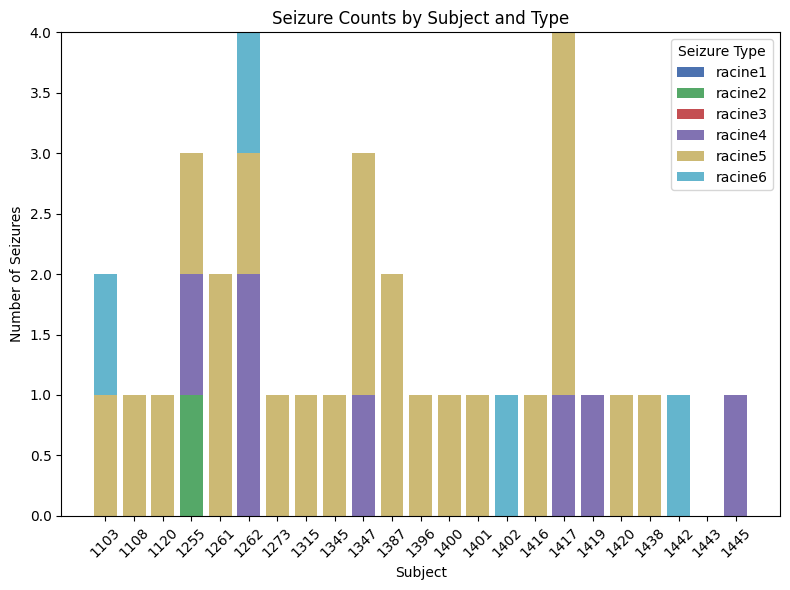

{'1103': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 1, 'racine6': 1}, '1108': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 1, 'racine6': 0}, '1120': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 1, 'racine6': 0}, '1255': {'racine1': 0, 'racine2': 1, 'racine3': 0, 'racine4': 1, 'racine5': 1, 'racine6': 0}, '1261': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 2, 'racine6': 0}, '1262': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 2, 'racine5': 1, 'racine6': 1}, '1273': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 1, 'racine6': 0}, '1315': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 1, 'racine6': 0}, '1345': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 0, 'racine5': 1, 'racine6': 0}, '1347': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4': 1, 'racine5': 2, 'racine6': 0}, '1387': {'racine1': 0, 'racine2': 0, 'racine3': 0, 'racine4

{'1103': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 1,
  'racine6': 1},
 '1108': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 1,
  'racine6': 0},
 '1120': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 1,
  'racine6': 0},
 '1255': {'racine1': 0,
  'racine2': 1,
  'racine3': 0,
  'racine4': 1,
  'racine5': 1,
  'racine6': 0},
 '1261': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 2,
  'racine6': 0},
 '1262': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 2,
  'racine5': 1,
  'racine6': 1},
 '1273': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 1,
  'racine6': 0},
 '1315': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 1,
  'racine6': 0},
 '1345': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,
  'racine4': 0,
  'racine5': 1,
  'racine6': 0},
 '1347': {'racine1': 0,
  'racine2': 0,
  'racine3': 0,

In [4]:
compare_seizure_counts(list(ptz_subjects.values()), seizure_colors)

## Seizure duration

Mean duration of Racine 4–6 events per animal, with individual seizures overlaid. Duration is marker end minus start, in seconds.

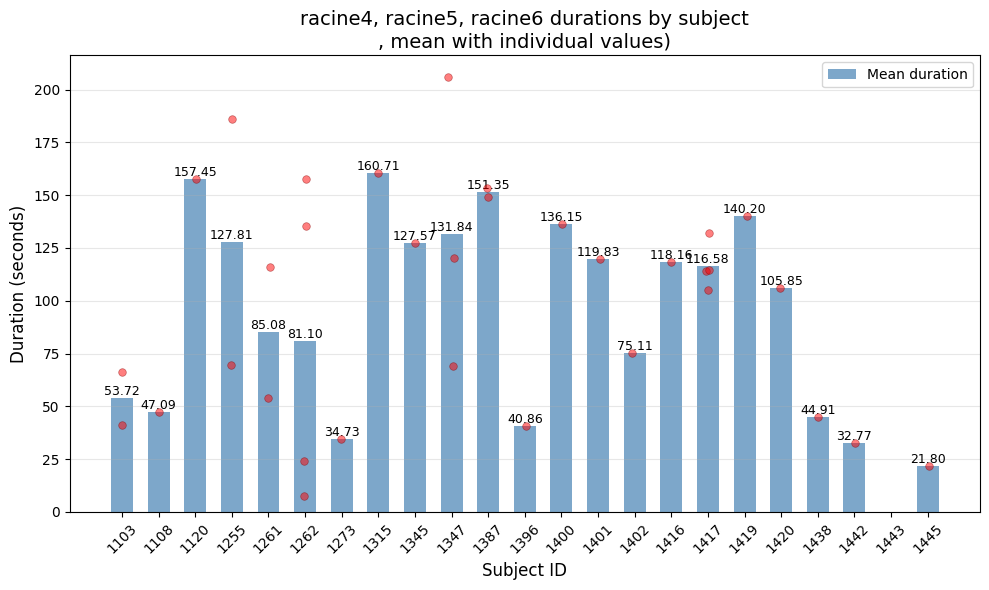

{'1103': {'avg': np.float64(53.71550000000002), 'durations': [66.41699999999992, 41.014000000000124]}, '1108': {'avg': np.float64(47.09199999999964), 'durations': [47.09199999999964]}, '1120': {'avg': np.float64(157.45299999999952), 'durations': [157.45299999999952]}, '1255': {'avg': np.float64(127.80749999999966), 'durations': [69.72499999999991, 185.88999999999942]}, '1261': {'avg': np.float64(85.07699999999977), 'durations': [53.96699999999964, 116.1869999999999]}, '1262': {'avg': np.float64(81.09500000000025), 'durations': [135.29500000000007, 7.442000000000007, 23.97100000000046, 157.67200000000048]}, '1273': {'avg': np.float64(34.73099999999977), 'durations': [34.73099999999977]}, '1315': {'avg': np.float64(160.71399999999994), 'durations': [160.71399999999994]}, '1345': {'avg': np.float64(127.57499999999982), 'durations': [127.57499999999982]}, '1347': {'avg': np.float64(131.83566666666616), 'durations': [69.18399999999997, 120.34799999999996, 205.97499999999854]}, '1387': {'avg

{'1103': {'avg': np.float64(53.71550000000002),
  'durations': [66.41699999999992, 41.014000000000124]},
 '1108': {'avg': np.float64(47.09199999999964),
  'durations': [47.09199999999964]},
 '1120': {'avg': np.float64(157.45299999999952),
  'durations': [157.45299999999952]},
 '1255': {'avg': np.float64(127.80749999999966),
  'durations': [69.72499999999991, 185.88999999999942]},
 '1261': {'avg': np.float64(85.07699999999977),
  'durations': [53.96699999999964, 116.1869999999999]},
 '1262': {'avg': np.float64(81.09500000000025),
  'durations': [135.29500000000007,
   7.442000000000007,
   23.97100000000046,
   157.67200000000048]},
 '1273': {'avg': np.float64(34.73099999999977),
  'durations': [34.73099999999977]},
 '1315': {'avg': np.float64(160.71399999999994),
  'durations': [160.71399999999994]},
 '1345': {'avg': np.float64(127.57499999999982),
  'durations': [127.57499999999982]},
 '1347': {'avg': np.float64(131.83566666666616),
  'durations': [69.18399999999997, 120.3479999999999

In [5]:
avg_marker_duration(list(ptz_subjects.values()), markers=['racine4', 'racine5', 'racine6'], avg='mean')

Longest Racine 4–6 event per animal (seconds). Complements the mean: a short mean with a long maximum indicates a single prolonged seizure.

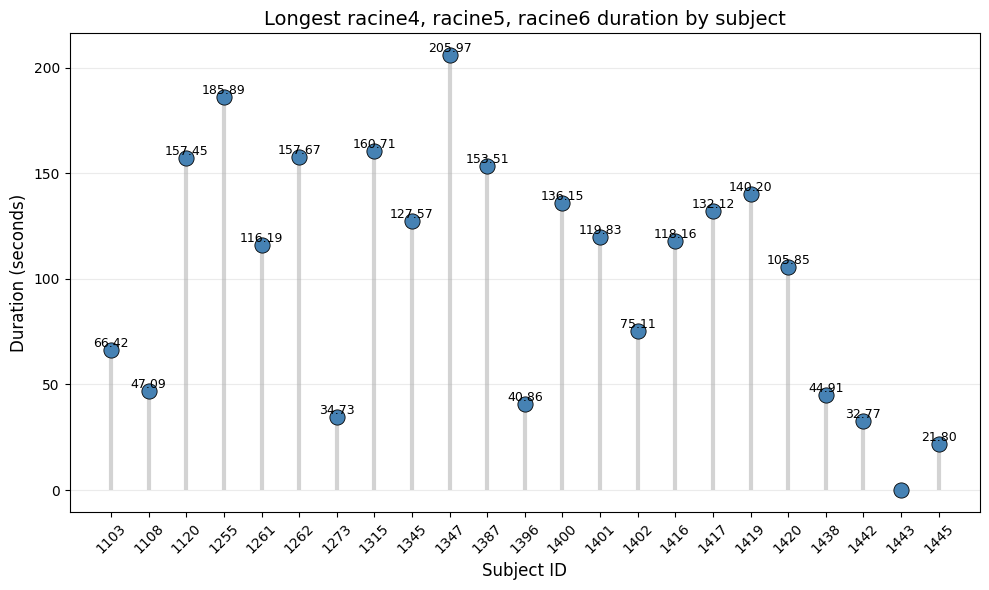

{'1103': 66.41699999999992, '1108': 47.09199999999964, '1120': 157.45299999999952, '1255': 185.88999999999942, '1261': 116.1869999999999, '1262': 157.67200000000048, '1273': 34.73099999999977, '1315': 160.71399999999994, '1345': 127.57499999999982, '1347': 205.97499999999854, '1387': 153.5139999999992, '1396': 40.86400000000049, '1400': 136.14900000000034, '1401': 119.83100000000013, '1402': 75.11299999999937, '1416': 118.16399999999976, '1417': 132.11799999999857, '1419': 140.19899999999961, '1420': 105.84699999999975, '1438': 44.91100000000006, '1442': 32.76500000000033, '1443': 0, '1445': 21.802999999999884}


{'1103': 66.41699999999992,
 '1108': 47.09199999999964,
 '1120': 157.45299999999952,
 '1255': 185.88999999999942,
 '1261': 116.1869999999999,
 '1262': 157.67200000000048,
 '1273': 34.73099999999977,
 '1315': 160.71399999999994,
 '1345': 127.57499999999982,
 '1347': 205.97499999999854,
 '1387': 153.5139999999992,
 '1396': 40.86400000000049,
 '1400': 136.14900000000034,
 '1401': 119.83100000000013,
 '1402': 75.11299999999937,
 '1416': 118.16399999999976,
 '1417': 132.11799999999857,
 '1419': 140.19899999999961,
 '1420': 105.84699999999975,
 '1438': 44.91100000000006,
 '1442': 32.76500000000033,
 '1443': 0,
 '1445': 21.802999999999884}

In [6]:
longest_marker_duration(list(ptz_subjects.values()), markers=['racine4', 'racine5', 'racine6'])

## Latency to generalized seizure

Time from the first PTZ injection to the first Racine 5 or 6 event on the challenge day. Animals without a matching target event are plotted as 0 s.

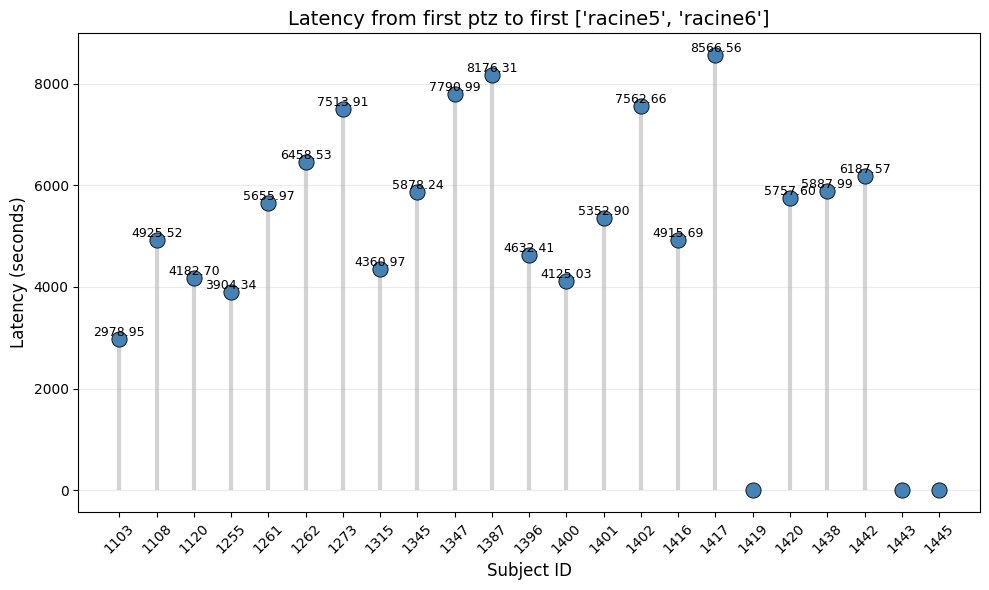

{'1103': 2978.951, '1108': 4925.516, '1120': 4182.703, '1255': 3904.335, '1261': 5655.969, '1262': 6458.531999999999, '1273': 7513.912, '1315': 4360.966, '1345': 5878.237, '1347': 7790.99, '1387': 8176.312000000001, '1396': 4632.409, '1400': 4125.0289999999995, '1401': 5352.898, '1402': 7562.659000000001, '1416': 4915.687, '1417': 8566.564, '1419': 0.0, '1420': 5757.597, '1438': 5887.995, '1442': 6187.573, '1443': 0.0, '1445': 0.0}


{'1103': 2978.951,
 '1108': 4925.516,
 '1120': 4182.703,
 '1255': 3904.335,
 '1261': 5655.969,
 '1262': 6458.531999999999,
 '1273': 7513.912,
 '1315': 4360.966,
 '1345': 5878.237,
 '1347': 7790.99,
 '1387': 8176.312000000001,
 '1396': 4632.409,
 '1400': 4125.0289999999995,
 '1401': 5352.898,
 '1402': 7562.659000000001,
 '1416': 4915.687,
 '1417': 8566.564,
 '1419': 0.0,
 '1420': 5757.597,
 '1438': 5887.995,
 '1442': 6187.573,
 '1443': 0.0,
 '1445': 0.0}

In [7]:
plot_latency(list(ptz_subjects.values()), from_marker='ptz', to_markers=['racine5', 'racine6'])

## PTZ doses until generalized seizure

Number of PTZ injections whose onset precedes the first Racine 4, 5, or 6 event. Animals lacking PTZ or target markers are omitted.

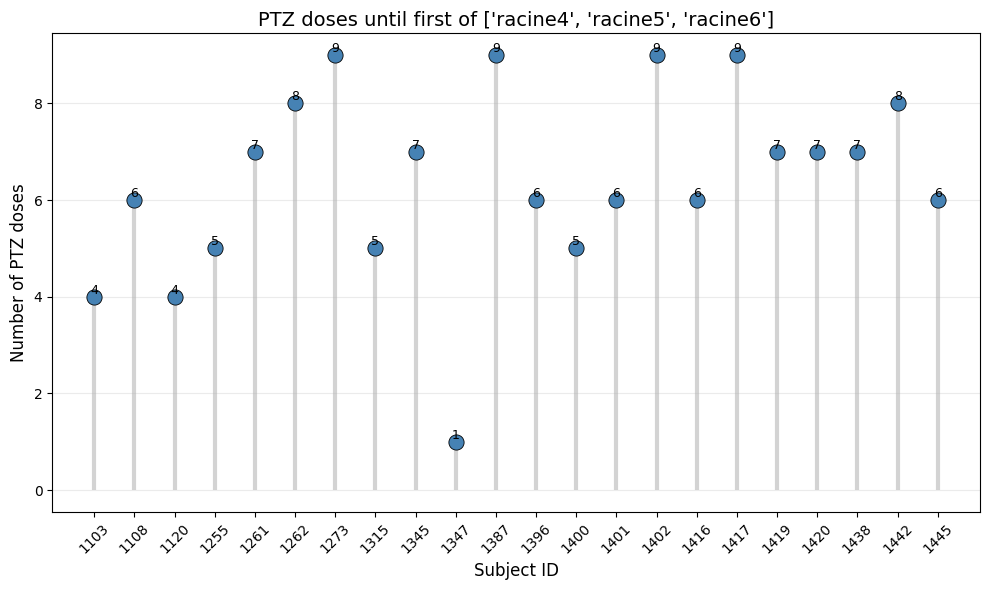

{'1103': 4, '1108': 6, '1120': 4, '1255': 5, '1261': 7, '1262': 8, '1273': 9, '1315': 5, '1345': 7, '1347': 1, '1387': 9, '1396': 6, '1400': 5, '1401': 6, '1402': 9, '1416': 6, '1417': 9, '1419': 7, '1420': 7, '1438': 7, '1442': 8, '1445': 6}


{'1103': 4,
 '1108': 6,
 '1120': 4,
 '1255': 5,
 '1261': 7,
 '1262': 8,
 '1273': 9,
 '1315': 5,
 '1345': 7,
 '1347': 1,
 '1387': 9,
 '1396': 6,
 '1400': 5,
 '1401': 6,
 '1402': 9,
 '1416': 6,
 '1417': 9,
 '1419': 7,
 '1420': 7,
 '1438': 7,
 '1442': 8,
 '1445': 6}

In [8]:
plot_ptz_doses_until_marker(list(ptz_subjects.values()), to_markers=['racine4', 'racine5', 'racine6'])